# B-factor visualization (aka sausage plot)

This notebook processes RMSF data and adds it to a PDB structure file to visualize the fluctuation in a 3D viewer such as PyMOL.

In [31]:
import glob
import os
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Load RMSF data for one or more variants.

In [32]:
# Update the variant_path to point to the correct data directory
# or duplicate to analyze multiple variants
WT_path = '../../data/1YVL_noNTD/WT'
T385M_path = '../../data/1YVL_noNTD/T385M'

In [33]:
# collect rmsf files
paths_prot = glob.glob(f'{WT_path}/rep*/analysis/001_qc/rmsf_prot.csv')

WT_rmsf_prot = []
for p in paths_prot:
    try:
        WT_rmsf_prot.append(pd.read_csv(p))
    except Exception as e:
        print(f"Warning: failed to read {p}: {e}")

In [34]:
# collect rmsf files
paths_prot = glob.glob(f'{T385M_path}/rep*/analysis/001_qc/rmsf_prot.csv')

T385M_rmsf_prot = []
for p in paths_prot:
    try:
        T385M_rmsf_prot.append(pd.read_csv(p))
    except Exception as e:
        print(f"Warning: failed to read {p}: {e}")


Compute mean square fluctuation (RMSF²) mean for each residue across replicates.

1. Square the RMSF values to get **MSF** (Mean Square Fluctuation).  
2. Average MSFs across replicates.  
3. Convert the mean MSF into **B-factors**.

**Formulas**

Root Mean Square Fluctuation (RMSF)  

$
\text{RMSF}_i = \sqrt{ \langle (\mathbf{r}_i(t) - \langle \mathbf{r}_i \rangle )^2 \rangle }
$

Mean Square Fluctuation (MSF)

$
\langle u^2 \rangle = \frac{1}{N} \sum_{i=1}^{N} (\text{RMSF}_i)^2
$

where \( N \) is the number of replicates.

B-factor Conversion

The crystallographic B-factor (also called the Debye–Waller factor) is related to MSF by:

$
B = \frac{8\pi^2}{3} \langle u^2 \rangle
$



In [35]:
def compute_mean_msf_bfactor(dfs, rmsf_cols):
    """
    Compute mean square fluctuation (MSF), RMSF_mean, and B-factor per residue
    across replicate dataframes.

    Parameters
    ----------
    dfs : list of pd.DataFrame
        List of replicate DataFrames, each containing RMSF columns.
    rmsf_cols : list of str
        Column names for RMSF values (e.g. ['RMSF_A', 'RMSF_B']).

    Returns
    -------
    pd.DataFrame
        DataFrame with Residue, MSF_mean, RMSF_mean, and B-factor columns.
    """
    # Conversion factor squared RMSF (MSF) → B-factor
    conversion_factor = (8 * np.pi**2) / 3

    # Compute squared RMSF columns
    dfs_with_msf = []
    for df in dfs:
        temp = df[['Residue']].copy()
        for col in rmsf_cols:
            msf_col = col.replace("RMSF", "MSF")
            temp[msf_col] = df[col]**2
        dfs_with_msf.append(temp)

    # Compute mean MSF per residue
    df_mean = pd.concat(dfs_with_msf).groupby("Residue").mean().reset_index()

    # Compute averaged RMSF and B-factor
    for col in rmsf_cols:
        msf_col = col.replace("RMSF", "MSF")
        bfact_col = col.replace("RMSF", "Bfactor")
        df_mean[bfact_col] = conversion_factor * df_mean[msf_col]

    return df_mean

In [36]:
WT_prot_means = compute_mean_msf_bfactor(
    dfs=WT_rmsf_prot,
    rmsf_cols=['RMSF_A', 'RMSF_B'],
)

In [37]:
WT_prot_means.head()

,Residue,MSF_A,MSF_B,Bfactor_A,Bfactor_B
0,1,11.866404,18.641532,312.311230,490.625459
1,2,6.338882,12.362304,166.832692,325.362810
2,3,4.547474,7.949262,119.684711,209.216192
3,4,4.186671,4.135694,110.188758,108.847109
4,5,3.325464,3.256883,87.522697,85.717729


Text(0.5, 0, 'Residue Number')

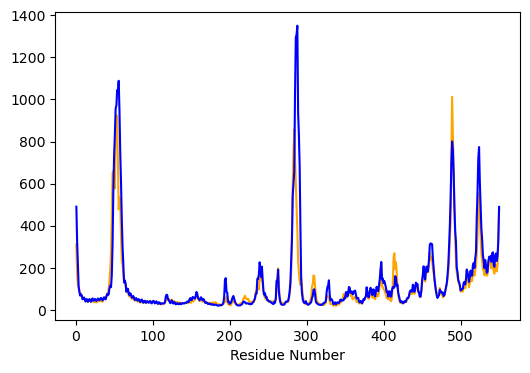

In [38]:
plt.figure(figsize=(6, 4))
plt.plot(WT_prot_means['Residue'], WT_prot_means['Bfactor_A'], label='Chain A B-factor', color='orange')
plt.plot(WT_prot_means['Residue'], WT_prot_means['Bfactor_B'], label='Chain B B-factor', color='blue')
plt.xlabel('Residue Number') 

In [39]:
WT_prot_means[WT_prot_means['Bfactor_A'] <10]

,Residue,MSF_A,MSF_B,Bfactor_A,Bfactor_B


In [40]:
WT_prot_means[WT_prot_means['Residue'] == 441-135]

,Residue,MSF_A,MSF_B,Bfactor_A,Bfactor_B
305,306,2.373253,1.397519,62.461521,36.781236


In [41]:
T385M_prot_means = compute_mean_msf_bfactor(
    dfs=T385M_rmsf_prot,
    rmsf_cols=['RMSF_A', 'RMSF_B'],
)

## Add mean RMSF values to PDB

### Single variant

In [42]:
def bfactor_to_pml(out_pdb, max, min=0, grey_range=None):
    """
    Generate PyMOL script to visualize B-factors as a sausage representation.

    Parameters
    ----------
    out_pdb : str
        Path to the PDB file with updated B-factors.
    out_pml : str
        Path to the output PyMOL script file.
    max : float
        Maximum B-factor value.
    """
    
    outdir = os.path.dirname(out_pdb)
    pdbfile = os.path.basename(out_pdb)
    structure = pdbfile.split('.')[0]

    pml_script = f"""
# Load the .pdb file (assuming it's in the current directory)
load {pdbfile}

# Display as sausage plot "putty" based on bfactor values
# Alternatively, select Action > Preset > b factor putty
preset.b_factor_putty("{structure}")
"""

    if min >= 0:
        pml_script += f"""
# Change gradient colors
spectrum b, white_red, "{structure}"
# Add colorbar
ramp_new b_ramp, {structure}, [{min}, {max}], [white, red]
    """
    else:
        pml_script += f"""
# Save bfactor values into a new variable p.q to use for coloring
alter {structure}, p.q = b
# Update bfactor values to absolute values for radius scaling
alter {structure}, b = abs(p.q)
rebuild

# Make putty radius depend on occupancy q instead of B-factor B
set cartoon_putty_scale_min, 0.5
set cartoon_putty_scale_max, 5.0

# Change gradient colors based on p.q values
spectrum p.q, blue_white_red, "{structure}"
# Add colorbar
ramp_new b_ramp, {structure}, [{min}, 0, {max}], [blue, white, red]
"""
        
    if grey_range is not None:
        start = grey_range[0]
        end = grey_range[1]
        pml_script += f"""
# Color residues in range {range} grey
color gray, ({structure} and not (resi {start}-{end}))
"""

    with open(f"{outdir}/{structure}_sausage.pml", "w") as f:
        f.write(pml_script)
        print(f"PyMOL script saved as {structure}_sausage.pml")

In [43]:
def bfactor_to_pdb(dfs, in_pdb, out_pdb, offset=0):
    """
    Replace B-factors in a PDB file with precomputed per-residue B-factors.

    Parameters
    ----------
    dfs : list of pd.DataFrame
        List of DataFrames containing B-factor columns for different chains.
    in_pdb : str
        Path to input PDB file
    out_pdb : str
        Path to output PDB file
    """

    # Map chain ID → {residue: B-factor}
    chain_b_map = {}

    for df in dfs:
        for col in df.columns:
            if col.startswith('Bfactor_'):
                chain = col.split('_', 1)[1]   # extract chain ID letter
                chain_b_map[chain] = dict(zip(df['Residue'], df[col]))

    # Flatten all B-factors to get min/max
    all_b_values = [val for d in chain_b_map.values() for val in d.values()]
    min_b = min(all_b_values)
    max_b = max(all_b_values)

    # Write new PDB with updated B-factors
    with open(in_pdb, "r") as infile, open(out_pdb, "w") as outfile:
        for line in infile:
            if line.startswith(("ATOM", "HETATM")):
                res_num = int(line[22:26].strip())
                chain_id = line[21].strip()
                if chain_id == 'C' or chain_id == 'D':
                    b_factor = chain_b_map.get(chain_id, {}).get(res_num, 0.0)
                else:
                    b_factor = chain_b_map.get(chain_id, {}).get(res_num - offset, 0.0)
                new_line = line[:60] + f"{b_factor:6.2f}" + line[66:]
                outfile.write(new_line)
            else:
                outfile.write(line)

    print(f"Modified PDB file saved as {out_pdb}")
    print(f"Minimum B-factor: {min_b:.2f}")
    print(f"Maximum B-factor: {max_b:.2f}")

    bfactor_to_pml(out_pdb, math.ceil(max_b))

Call the function defined in the previous cell.

In [44]:
bfactor_to_pdb([WT_prot_means], 
               "../../data/1YVL_noNTD/WT/WT_QP.pdb", 
               "../../data/1YVL_noNTD/WT/bfactor_mean.pdb", 
               offset=133)

Modified PDB file saved as ../../data/1YVL_noNTD/WT/bfactor_mean.pdb
Minimum B-factor: 19.91
Maximum B-factor: 1350.54
PyMOL script saved as bfactor_mean_sausage.pml


### Difference in means between two variants

In [45]:
def bfact_mean_diff_to_pdb(T385M, WT_prot_stats, T385M_prot_stats, in_pdb, out_pdb, offset = 0, range=None):

    if range is not None:
        WT_prot_stats = WT_prot_stats[(WT_prot_stats['Residue'] >= range[0] - offset) & (WT_prot_stats['Residue'] <= range[1] - offset)]
        T385M_prot_stats = T385M_prot_stats[(T385M_prot_stats['Residue'] >= range[0] - offset) & (T385M_prot_stats['Residue'] <= range[1] - offset)]

    # Merge DataFrames on Residue
    merged_df = pd.merge(
        WT_prot_stats[['Residue', 'Bfactor_A', 'Bfactor_B']],
        T385M_prot_stats[['Residue', 'Bfactor_A', 'Bfactor_B']],
        on='Residue',
        suffixes=('_WT', f'_{T385M}')
    )

    chain_b_map = {}
    # Calculate differences (T385M - WT) for each chain and store in dicts
    for chain in ['A', 'B']:
        merged_df[f'Bfactor_{chain}_diff'] = (
            merged_df[f'Bfactor_{chain}_WT'] - merged_df[f'Bfactor_{chain}_{T385M}']
        )
        chain_b_map[chain] = dict(zip(merged_df['Residue'], merged_df[f'Bfactor_{chain}_diff']))

    # Determine min/max for colorbar (use larger range from chain A or B)
    min_diff = merged_df.filter(like='_diff').to_numpy().min()
    max_diff = merged_df.filter(like='_diff').to_numpy().max()

    # Modify PDB file to assign B-factor differences to B-factor column for specified range
    with open(in_pdb, "r") as infile, open(out_pdb, "w") as outfile:
        for line in infile:
            if line.startswith(("ATOM", "HETATM")):
                res_num = int(line[22:26].strip())
                chain_id = line[21].strip()
                b_factor = chain_b_map.get(chain_id, {}).get(res_num - offset, 0.0)
                b_factor_str = f"{b_factor:6.2f}"
                new_line = line[:60] + b_factor_str + line[66:]
                outfile.write(new_line)
            else:
                outfile.write(line)

    print(f"PDB file with B-factor differences in protein between WT and T385Mants saved as {out_pdb}")
    print(f"B-factor difference range: {min_diff:.2f} to {max_diff:.2f}")

    if range is not None:
        bfactor_to_pml(out_pdb, math.ceil(max_diff), math.floor(min_diff), grey_range=range)
    else:
        bfactor_to_pml(out_pdb, math.ceil(max_diff), math.floor(min_diff))

Call the function defined in the previous cell.

In [46]:
bfact_mean_diff_to_pdb('T385M', WT_prot_means, T385M_prot_means, 
                       "../../data/1YVL_noNTD/WT/WT_QP.pdb", 
                       "../../data/1YVL_noNTD/bfactor_diff_WT-T385M.pdb", 
                       offset=133)

PDB file with B-factor differences in protein between WT and T385Mants saved as ../../data/1YVL_noNTD/bfactor_diff_WT-T385M.pdb
B-factor difference range: -1080.26 to 683.88
PyMOL script saved as bfactor_diff_WT-T385M_sausage.pml
